# Reproduce the CAAdapFL paper evidence

**Marked5 • release candidate1.2.0 • Apache2.0 software**

This executed companion checks and explores the four completed studies. Install
all six result assets with `python benchmark.py install --assets PATH` first.
Every cell reads immutable evidence; no cell trains a model or selects a new
hypothesis. Full independent uncertainty/cost QA and saved-state replay are
separate explicit commands in README. The 2017–2024 evaluation has been inspected
before these follow-ups and is not a new untouched test.

IMD input values are excluded from the public deposit. All output scores are
available; the IMD-added feature/state replay needs local native import. Figures
in this notebook are explanatory redraws, not exact manuscript image layouts.

In [1]:
from pathlib import Path
import hashlib, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'benchmark.py').is_file())
B = ROOT/'benchmarks/accepted'
H = ROOT/'benchmarks/sharing'
def read_csv(path):
    return pd.read_csv(path, float_precision='round_trip')
def sha(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
for path in [B/'runs/revision_v2/evaluation/complete.json',
             B/'runs/supplements_v2/evaluation/complete.json',
             B/'runs/revision_v3/evaluation/complete.json',
             H/'evaluation/complete.json']:
    assert path.is_file(), 'Install all result assets before executing this notebook.'
plt.rcParams.update({'font.size':10, 'figure.dpi':130, 'axes.spines.top':False, 'axes.spines.right':False})
print('Snapshot companions ready; Python', platform.python_version())

Snapshot companions ready; Python 3.12.14


## Completed studies and fit boundaries

Fit bundles are distinct from output labels, checkpoint aliases and estimator
operations. Primary 283; source controls 90; capacity 100; information sharing 40.
Climatology is a no-fit label. Capacity includes authenticated carried historical
predictions as well as new fits; the state-replay receipt separates these scopes.

In [2]:
inventory = pd.DataFrame([
    ['primary',283,96,230400], ['source controls',90,36,83100],
    ['capacity/output',100,46,110400], ['sharing/all endpoints',40,9,64800]],
    columns=['study','completed_fit_bundles','output_labels','forecast_rows'])
assert inventory.completed_fit_bundles.sum()==513
display(inventory)
counts = {
    'primary':len(read_csv(B/'runs/revision_v2/evaluation/raw_predictions.csv')),
    'sources':len(read_csv(B/'runs/supplements_v2/evaluation/raw_predictions_all_cases.csv')),
    'capacity':len(read_csv(B/'runs/revision_v3/evaluation/raw_predictions.csv')),
    'sharing':len(read_csv(H/'evaluation/raw_predictions_ALL_endpoints.csv'))}
assert list(counts.values())==[230400,83100,110400,64800]
print('All four released forecast counts match:', counts)

,study,completed_fit_bundles,output_labels,forecast_rows
0,primary,283,96,230400
1,source controls,90,36,83100
2,capacity/output,100,46,110400
3,sharing/all endpoints,40,9,64800


All four released forecast counts match: {'primary': 230400, 'sources': 83100, 'capacity': 110400, 'sharing': 64800}


## Independent primary metric aggregation

Compute each client's 96-month R² and RMSE independently, average across the
five fixed clients for each seed, then summarize five seeds (sample SD). This
preserves the equal-client estimand. Computing one pooled RMSE would change it.
The check covers all 96 primary output labels, including separately matched
latency controls. It is a bounded arithmetic check, not the complete QA command.

In [3]:
raw = read_csv(B/'runs/revision_v2/evaluation/raw_predictions.csv')
assert not raw.duplicated(['model','seed','client','target_month']).any()
rows=[]
for (model,seed,client), g in raw.groupby(['model','seed','client'],sort=True):
    y=g.y.to_numpy(float); pred=g.prediction.to_numpy(float)
    assert len(y)==96 and np.isfinite(y).all() and np.isfinite(pred).all()
    rows.append(dict(model=model,seed=seed,client=client,
                     R2=1-np.sum((pred-y)**2)/np.sum((y-y.mean())**2),
                     RMSE_mm=float(np.sqrt(np.mean((pred-y)**2)))))
per_client=pd.DataFrame(rows)
per_seed=per_client.groupby(['model','seed'])[['R2','RMSE_mm']].mean()
independent=per_seed.groupby('model').agg(['mean','std'])
independent.columns=['_'.join(c) for c in independent.columns]
published=read_csv(B/'runs/revision_v2/evaluation/seed_summary.csv').set_index('model')
assert independent.index.equals(published.sort_index().index)
errors=(independent-published.reindex(independent.index)[independent.columns]).abs()
assert np.nanmax(errors.to_numpy())<1e-10
print('Independent96-label metric check PASS; maximum difference:', float(np.nanmax(errors.to_numpy())))

Independent96-label metric check PASS; maximum difference: 1.4210854715202004e-14


## Main comparisons and source controls

The following main labels share the same declared primary cohort. Source-control
comparisons must remain within each source's matched REFERENCE/ADDED cohort.
IMD has425 admitted evaluation client-months per seed; solar and GLDAS21 have480.
Different availability periods make cross-source ranking inappropriate.

In [4]:
keys=['CAAA_GLOBAL_FULL','FEDAVG_GLOBAL_FULL','FEDPROX_GLOBAL_FULL',
      'CENTRAL_GLOBAL_FULL','LOCAL_PERSONAL_FULL','training_seasonal_mean']
main=published.loc[keys,['R2_mean','R2_std','RMSE_mm_mean','RMSE_mm_std','MAE_mm_mean']]
display(main.round(6))
sources=read_csv(B/'runs/supplements_v2/evaluation/seed_summary_all_cases.csv')
display(sources[['case','model','R2_mean','RMSE_mm_mean']].round(6))
print('IMD input/scaler rederivation available locally:', (B/'tools/derived/imd/imd_supplement.csv').exists())

,R2_mean,R2_std,RMSE_mm_mean,RMSE_mm_std,MAE_mm_mean
model,,,,,
CAAA_GLOBAL_FULL,0.755296,0.007886,52.868061,1.248923,36.256533
FEDAVG_GLOBAL_FULL,0.758075,0.006021,51.870653,0.857804,35.069293
FEDPROX_GLOBAL_FULL,0.756083,0.008035,52.814186,1.245715,36.271938
CENTRAL_GLOBAL_FULL,0.805034,0.008046,47.221712,0.663729,30.170946
LOCAL_PERSONAL_FULL,0.800846,0.008847,49.042149,1.187041,31.971944
training_seasonal_mean,0.815193,0.000000,45.643805,0.000000,27.255555


,case,model,R2_mean,RMSE_mm_mean
0,IMD,CAAA_GLOBAL_IMD_ADDED,0.746390,53.372889
1,IMD,CAAA_GLOBAL_IMD_REFERENCE,0.748088,53.236472
2,IMD,CAAA_PERSONAL_IMD_ADDED,0.782852,48.916575
3,IMD,CAAA_PERSONAL_IMD_REFERENCE,0.799917,47.989244
4,IMD,FEDAVG_GLOBAL_IMD_ADDED,0.749226,52.124717
5,IMD,FEDAVG_GLOBAL_IMD_REFERENCE,0.750193,52.369693
6,IMD,FEDAVG_PERSONAL_IMD_ADDED,0.801061,48.100028
7,IMD,FEDAVG_PERSONAL_IMD_REFERENCE,0.803425,47.694203
8,IMD,FEDPROX_GLOBAL_IMD_ADDED,0.744176,53.533675
9,IMD,FEDPROX_GLOBAL_IMD_REFERENCE,0.748989,53.176440


IMD input/scaler rederivation available locally: False


## Capacity and active components

The exploratory 100-fit capacity/output study uses matched prespecified controls
after examining the historical evaluation. Its own tables and uncertainty
receipts, rather than unrelated systems_v4 results, support Supplement S11–S16.
Below is the full saved result summary; output aliases do not increase fit count.

In [5]:
capacity=read_csv(B/'runs/revision_v3/evaluation/seed_summary.csv')
assert capacity.model.nunique()==46
display(capacity[['model','R2_mean','RMSE_mm_mean','MAE_mm_mean']].round(6))
print('Capacity completion:', json.loads((B/'runs/revision_v3/evaluation/complete.json').read_text())['status'])

,model,R2_mean,RMSE_mm_mean,MAE_mm_mean
0,ADAPTIVE_OFF,0.770688,50.944890,34.326828
1,BOTH_OFF,0.761153,52.198373,35.635388
2,CAAA_CLIPPED_RAW,0.772801,50.708807,33.226248
3,CAAA_GLOBAL_CLIMATE_V2,0.739135,54.755698,37.530829
4,CAAA_GLOBAL_CORE_V2,0.760750,52.983165,36.182737
5,CAAA_GLOBAL_FULL_V2,0.755296,52.868061,36.256533
6,CAAA_NONNEGATIVE,0.775543,50.229843,31.852121
7,CAAA_NONNEGATIVE_TAIL2,0.765405,51.555032,33.066289
8,CAAA_PERSONAL_FULL_V2,0.807609,47.434390,30.219542
9,CAAA_RAW,0.770577,50.929164,34.300361


Capacity completion: COMPLETE


## Information sharing: accuracy and required payload

Eight trained policies use five paired seeds and fixed distributed local update
budgets. Tick60 is primary; common 20/40/60 selected checkpoints are sensitivity.
Required uncompressed logical payloads count sender/recipient delivery, not
measured WAN transfers. Local-private payload is zero within this experiment,
which does not establish a formal privacy guarantee. Central engineered upload
is contextual, not a minimal raw-source transfer estimate. Annual sign tests
and both six/seven multiplicity families are retained in the full evidence.

,R2_mean,RMSE_mm_mean,MSESS_mean,required_payload_bytes
model,,,,
CAAA_STATS_K1,0.768041,50.812993,-0.247503,41945560.0
CENTRAL_POOL_STATS,0.721990,55.967003,-0.538732,6613680.0
FEDAVG_PRIVATE_K1,0.724770,56.046493,-0.540062,41938640.0
FEDAVG_STATS_K1,0.753472,52.604807,-0.347398,41945560.0
FEDAVG_STATS_K20,0.666812,61.131469,-0.918523,2433160.0
FEDAVG_STATS_K5,0.716585,55.407044,-0.494153,8671960.0
LOCAL_PRIVATE,0.699445,58.591252,-0.719364,0.0
LOCAL_STATS,0.699252,59.245034,-0.751674,6920.0
TRAIN_CLIMATOLOGY,0.815193,45.643805,0.000000,NaN


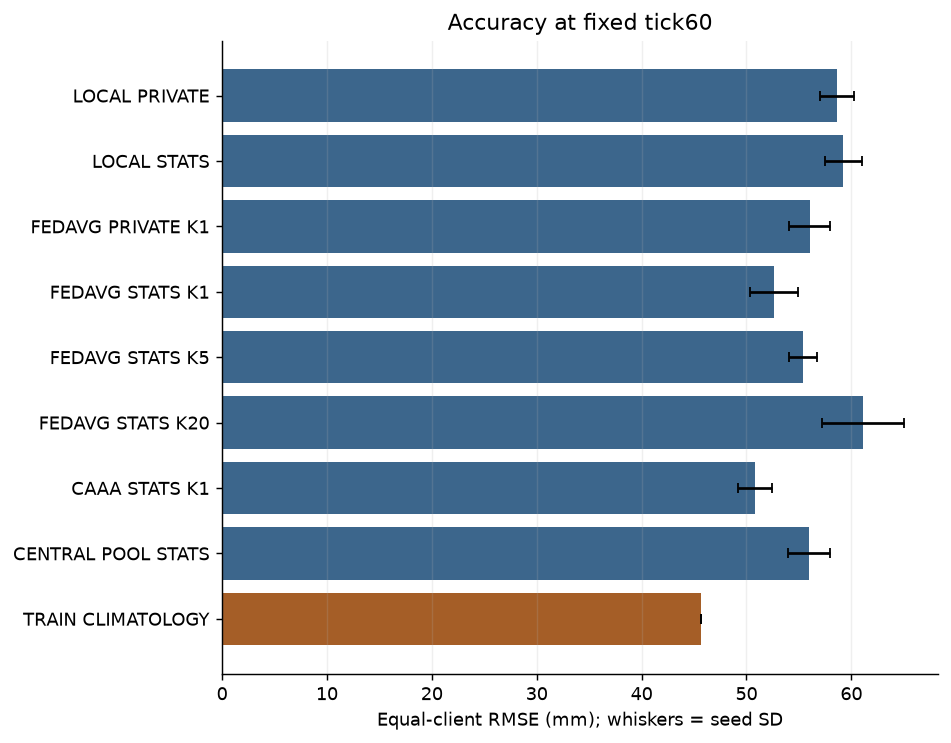

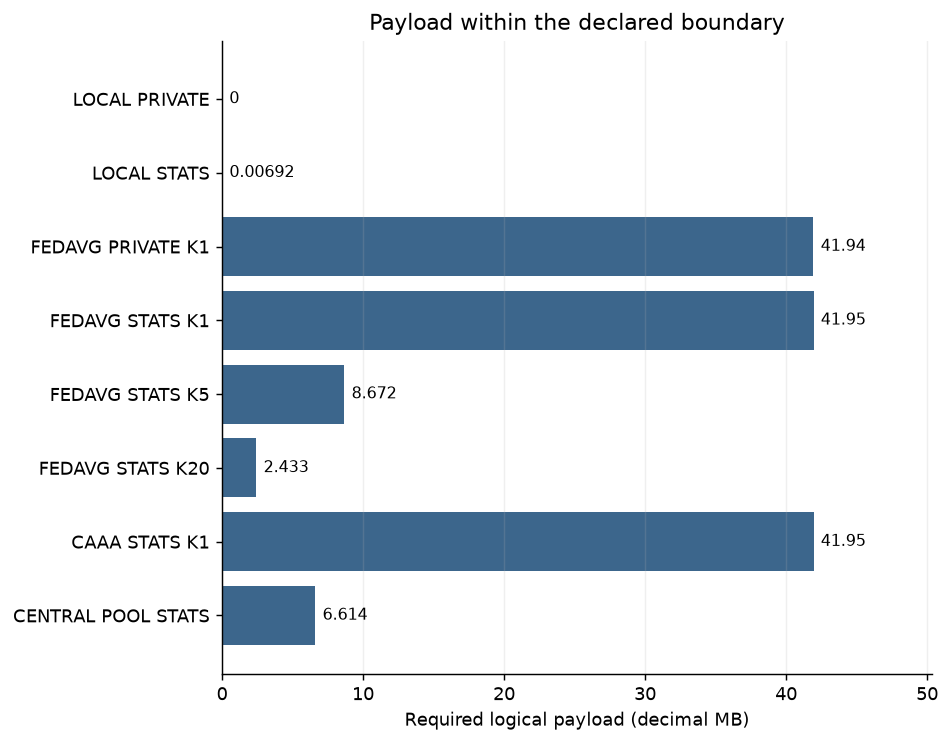

In [6]:
sharing=read_csv(H/'evaluation/principal_comparison.csv').set_index('model')
cost=read_csv(H/'evaluation/fit_cost_40.csv')
assert len(cost)==40 and cost.groupby('model').seed.nunique().eq(5).all()
payload=cost.groupby('model').logical_required_payload_bytes.mean()
joined=sharing.join(payload.rename('required_payload_bytes'))
display(joined[['R2_mean','RMSE_mm_mean','MSESS_mean','required_payload_bytes']].round(6))
assert sharing.loc['TRAIN_CLIMATOLOGY','MSESS_mean']==0
assert joined.loc['LOCAL_PRIVATE','required_payload_bytes']==0
order=['LOCAL_PRIVATE','LOCAL_STATS','FEDAVG_PRIVATE_K1','FEDAVG_STATS_K1',
       'FEDAVG_STATS_K5','FEDAVG_STATS_K20','CAAA_STATS_K1','CENTRAL_POOL_STATS','TRAIN_CLIMATOLOGY']
labels=[x.replace('_',' ') for x in order]
scores=joined.reindex(order)
colors=['#3C668C']*8+['#A55E27']
fig,ax=plt.subplots(figsize=(7.2,5.6),layout='constrained')
ax.barh(labels,scores.RMSE_mm_mean,xerr=scores.RMSE_mm_std,color=colors,capsize=3)
ax.invert_yaxis();ax.set(xlabel='Equal-client RMSE (mm); whiskers = seed SD',title='Accuracy at fixed tick60')
ax.grid(axis='x',alpha=.2)
plt.show()
model_order=order[:-1]
fig,ax=plt.subplots(figsize=(7.2,5.6),layout='constrained')
values=scores.loc[model_order,'required_payload_bytes']/1e6
bars=ax.barh(labels[:-1],values,color=colors[:-1])
ax.bar_label(bars,labels=[f'{v:.4g}' for v in values],padding=4,fontsize=9)
ax.set_xlim(0,values.max()*1.2)
ax.invert_yaxis();ax.set(xlabel='Required logical payload (decimal MB)',title='Payload within the declared boundary')
ax.grid(axis='x',alpha=.2)
plt.show()

## Audit trail and next commands

The release manifests bind source and six result archives. Independent full
verification recomputes uncertainty/costs without production scoring helpers;
state replay validates frozen checkpoint inference on its recorded environment.
The public IMD output arithmetic check cannot certify the omitted IMD inputs.
Acquiring/importing exact native inputs restores those checks locally.

```text
python benchmark.py verify --suite all
python benchmark.py replay --suite all
python benchmark.py tables --output publication/tables_new
python benchmark.py figures --output publication/figures_new
```

All 45 manuscript/supplement items are mapped in
`metadata/paper_evidence_map.json`. No optimization, new training, untouched
holdout, institutional deployment or secure privacy claim is made by this notebook.

In [7]:
assets=json.loads((ROOT/'metadata/release_assets.json').read_text())
print('Result assets:',len(assets['assets']), 'compressed bytes:',sum(x['bytes'] for x in assets['assets']))
assert len(assets['assets'])==6 and all(x['bytes']<2*1024**3 for x in assets['assets'])
identity_files=[B/'runs/revision_v2/run_identity.json',B/'runs/supplements_v2/run_identity.json',
                B/'runs/revision_v3/choices_frozen.json',H/'run/choices_frozen.json']
for path in identity_files:
    assert path.is_file(), 'Frozen identity unavailable'
    print(path.relative_to(ROOT).as_posix(),sha(path))
print('COMPANION_PASS: no model fitting, no network calls, no evidence writes.')

Result assets: 6 compressed bytes: 5964009578
benchmarks/accepted/runs/revision_v2/run_identity.json 028ff3e9b375c11ab4e4d767b97da10306ad73bba448697afa1ea326d67b79e9
benchmarks/accepted/runs/supplements_v2/run_identity.json 5d5d7b70bcc2860172243fc15719dcf5911887e333530e25d892a5b821a9f26d
benchmarks/accepted/runs/revision_v3/choices_frozen.json 7b5624adeccd9ec9c5186141ac136e56c5b79f0bc1457173a2c74dbf46fc937b
benchmarks/sharing/run/choices_frozen.json 66119bd279c1e6513028cfec0c59758762eb37e768a4bbdbb4cf31b76121009c
COMPANION_PASS: no model fitting, no network calls, no evidence writes.
